In [ ]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/flipkart-product-review-dataset/flipkart_product.csv


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import datetime as dt
import warnings
warnings.filterwarnings("ignore")
warnings.simplefilter("ignore")

In [10]:
df = pd.read_csv('/kaggle/input/flipkart-product-review-dataset/flipkart_product.csv', encoding='latin1')

In [11]:
df.head()

,ProductName,Price,Rate,Review,Summary
0,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",5,Super!,Great cooler.. excellent air flow and for this...
1,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",5,Awesome,Best budget 2 fit cooler. Nice cooling
2,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",3,Fair,The quality is good but the power of air is de...
3,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",1,Useless product,Very bad product it's a only a fan
4,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",3,Fair,Ok ok product


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 189874 entries, 0 to 189873
Data columns (total 5 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   ProductName  189874 non-null  object
 1   Price        189873 non-null  object
 2   Rate         189873 non-null  object
 3   Review       189870 non-null  object
 4   Summary      189860 non-null  object
dtypes: object(5)
memory usage: 7.2+ MB


In [13]:
df.isna().sum()

ProductName     0
Price           1
Rate            1
Review          4
Summary        14
dtype: int64

In [14]:
df.nunique()

ProductName      812
Price            561
Rate               9
Review          1264
Summary        98343
dtype: int64

In [16]:
# Check for rows where Price can't be converted to float
def is_numeric(val):
    try:
        float(val.replace('₹', '').replace(',', ''))
        return True
    except:
        return False

# Find problematic rows
problematic_rows = df[~df['Price'].apply(is_numeric)]
print(problematic_rows[['Price']])

           Price
0       ??3,999
1       ??3,999
2       ??3,999
3       ??3,999
4       ??3,999
...          ...
189868    â¹142
189869    â¹142
189870    â¹142
189871    â¹142
189872    â¹142

[189860 rows x 1 columns]


In [17]:
import pandas as pd
import re

# Function to clean Price
def clean_price(price):
    if pd.isna(price):  # Handle NaN values
        return None
    # Remove ₹ and commas, then keep only digits and decimal points
    price = str(price).replace('₹', '').replace(',', '')
    # Extract only numbers (and optionally a decimal point)
    cleaned = re.sub(r'[^0-9.]', '', price)
    return cleaned if cleaned else None  # Return None if no numbers found

# Apply cleaning
df['Price_Cleaned'] = df['Price'].apply(clean_price)

# Convert to float
df['Price_Cleaned'] = pd.to_numeric(df['Price_Cleaned'], errors='coerce')

# Check how many rows failed to convert
print("Rows with NaN Price after cleaning:", df['Price_Cleaned'].isna().sum())

Rows with NaN Price after cleaning: 0


In [18]:
# Drop rows where Price_Cleaned is NaN
df = df.dropna(subset=['Price_Cleaned'])

In [19]:
median_price = df['Price_Cleaned'].median()
df['Price_Cleaned'] = df['Price_Cleaned'].fillna(median_price)

In [20]:
# Check a sample of the cleaned prices
print(df[['Price', 'Price_Cleaned']].head(10))

      Price  Price_Cleaned
0  ??3,999         3999.0
1  ??3,999         3999.0
2  ??3,999         3999.0
3  ??3,999         3999.0
4  ??3,999         3999.0
5  ??3,999         3999.0
6  ??3,999         3999.0
7  ??3,999         3999.0
8  ??3,999         3999.0
9  ??3,999         3999.0


In [21]:
import re

# 1. Handle missing values
df = df.dropna(subset=['Summary'])  # Drop rows where Summary is missing
df['Review'] = df['Review'].fillna('No review')  # Fill missing Review with placeholder

# 2. Clean Price (remove ₹ and convert to numeric)
def clean_price(price):
    if pd.isna(price):
        return None
    price = str(price).replace('₹', '').replace(',', '')
    cleaned = re.sub(r'[^0-9.]', '', price)
    return cleaned if cleaned else None

df['Price_Cleaned'] = df['Price'].apply(clean_price)
df['Price_Cleaned'] = pd.to_numeric(df['Price_Cleaned'], errors='coerce')

# Drop or impute NaN prices
df = df.dropna(subset=['Price_Cleaned'])  # Dropping for simplicity

# 3. Clean Rate (convert to integer, handle odd values)
df['Rate'] = pd.to_numeric(df['Rate'], errors='coerce')
df = df.dropna(subset=['Rate'])
df['Rate'] = df['Rate'].astype(int)

# 4. Clean ProductName (remove weird characters)
df['ProductName'] = df['ProductName'].apply(lambda x: re.sub(r'[^a-zA-Z0-9\s]', '', x))

# 5. Basic text cleaning for Review and Summary
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    return text

df['Review'] = df['Review'].apply(clean_text)
df['Summary'] = df['Summary'].apply(clean_text)

# Verify the cleaned data
print(df[['Price', 'Price_Cleaned', 'Rate', 'ProductName']].head())

      Price  Price_Cleaned  Rate  \
0  ??3,999         3999.0     5   
1  ??3,999         3999.0     5   
2  ??3,999         3999.0     3   
3  ??3,999         3999.0     1   
4  ??3,999         3999.0     3   

                                         ProductName  
0  Candes 12 L RoomPersonal Air CoolerWhite Black...  
1  Candes 12 L RoomPersonal Air CoolerWhite Black...  
2  Candes 12 L RoomPersonal Air CoolerWhite Black...  
3  Candes 12 L RoomPersonal Air CoolerWhite Black...  
4  Candes 12 L RoomPersonal Air CoolerWhite Black...  


In [22]:
# Check unique values in Rate
print("Unique Rate values:", df['Rate'].unique())

Unique Rate values: [5 3 1 4 2]


In [23]:
# Map ratings to sentiment
def rate_to_sentiment(rate):
    if rate >= 4:
        return 'Positive'
    elif rate <= 2:
        return 'Negative'
    else:
        return 'Neutral'

df['Sentiment_From_Rate'] = df['Rate'].apply(rate_to_sentiment)

# Check distribution of sentiment based on ratings
print(df['Sentiment_From_Rate'].value_counts())

Sentiment_From_Rate
Positive    148335
Negative     25841
Neutral      15680
Name: count, dtype: int64


In [24]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk

# Download VADER lexicon
nltk.download('vader_lexicon')

# Initialize VADER
sia = SentimentIntensityAnalyzer()

# Apply VADER to Summary column
df['Sentiment_Score'] = df['Summary'].apply(lambda x: sia.polarity_scores(x)['compound'])

# Classify sentiment based on score
def classify_sentiment(score):
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

df['Sentiment_From_Text'] = df['Sentiment_Score'].apply(classify_sentiment)

# Check distribution of text-based sentiment
print(df['Sentiment_From_Text'].value_counts())

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /usr/share/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
Sentiment_From_Text
Positive    150377
Negative     22023
Neutral      17456
Name: count, dtype: int64


In [25]:
# Create a cross-tabulation to compare the two
comparison = pd.crosstab(df['Sentiment_From_Rate'], df['Sentiment_From_Text'])
print(comparison)

# Calculate agreement rate
agreement = (df['Sentiment_From_Rate'] == df['Sentiment_From_Text']).mean()
print(f"Agreement between Rate-based and Text-based sentiment: {agreement:.2%}")

Sentiment_From_Text  Negative  Neutral  Positive
Sentiment_From_Rate                             
Negative                17327     5619      2895
Neutral                  2597     2643     10440
Positive                 2099     9194    137042
Agreement between Rate-based and Text-based sentiment: 82.70%


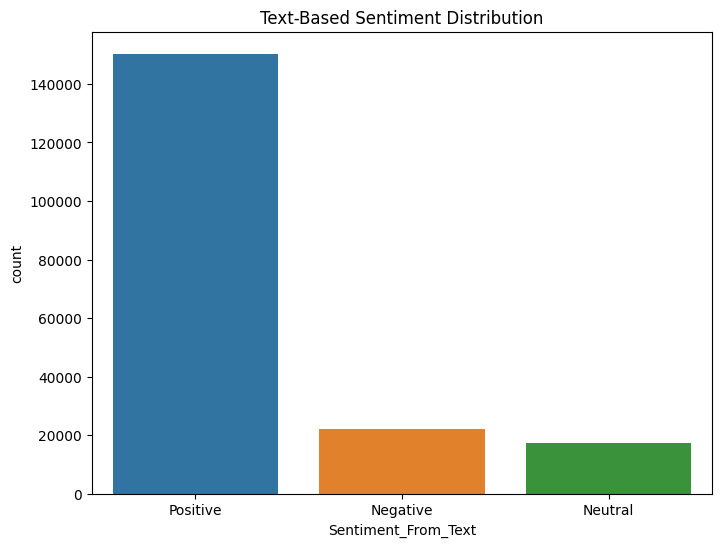

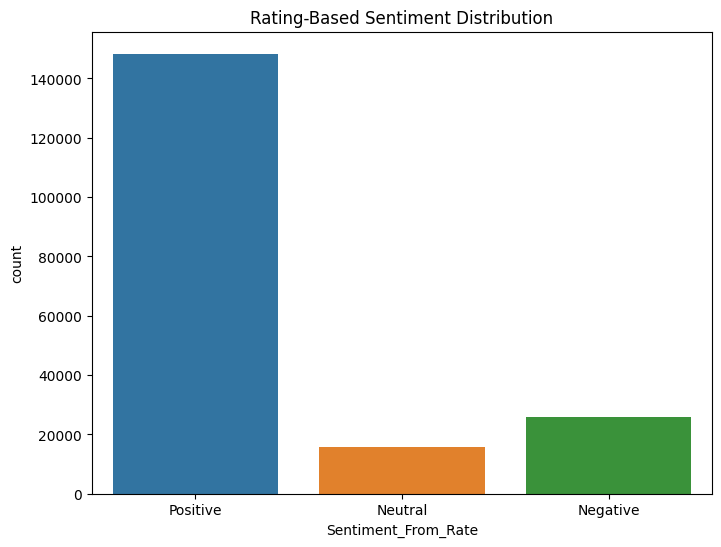

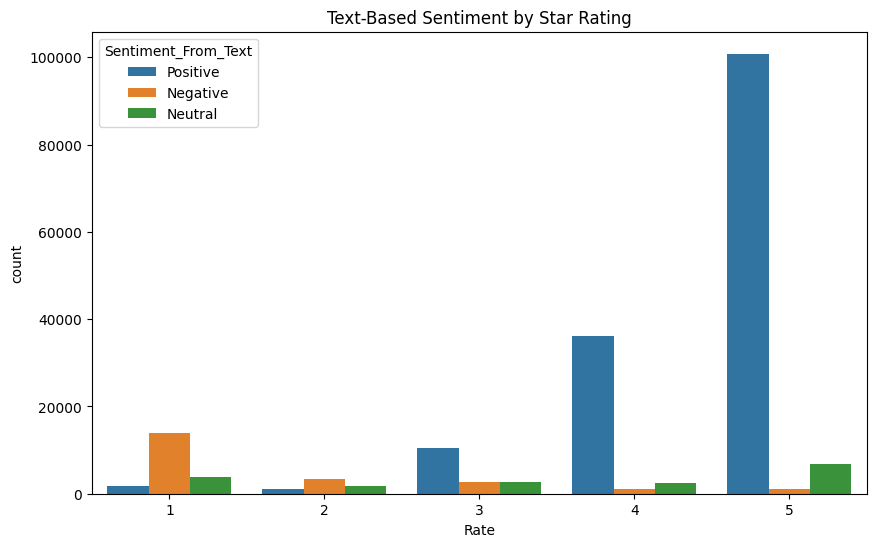

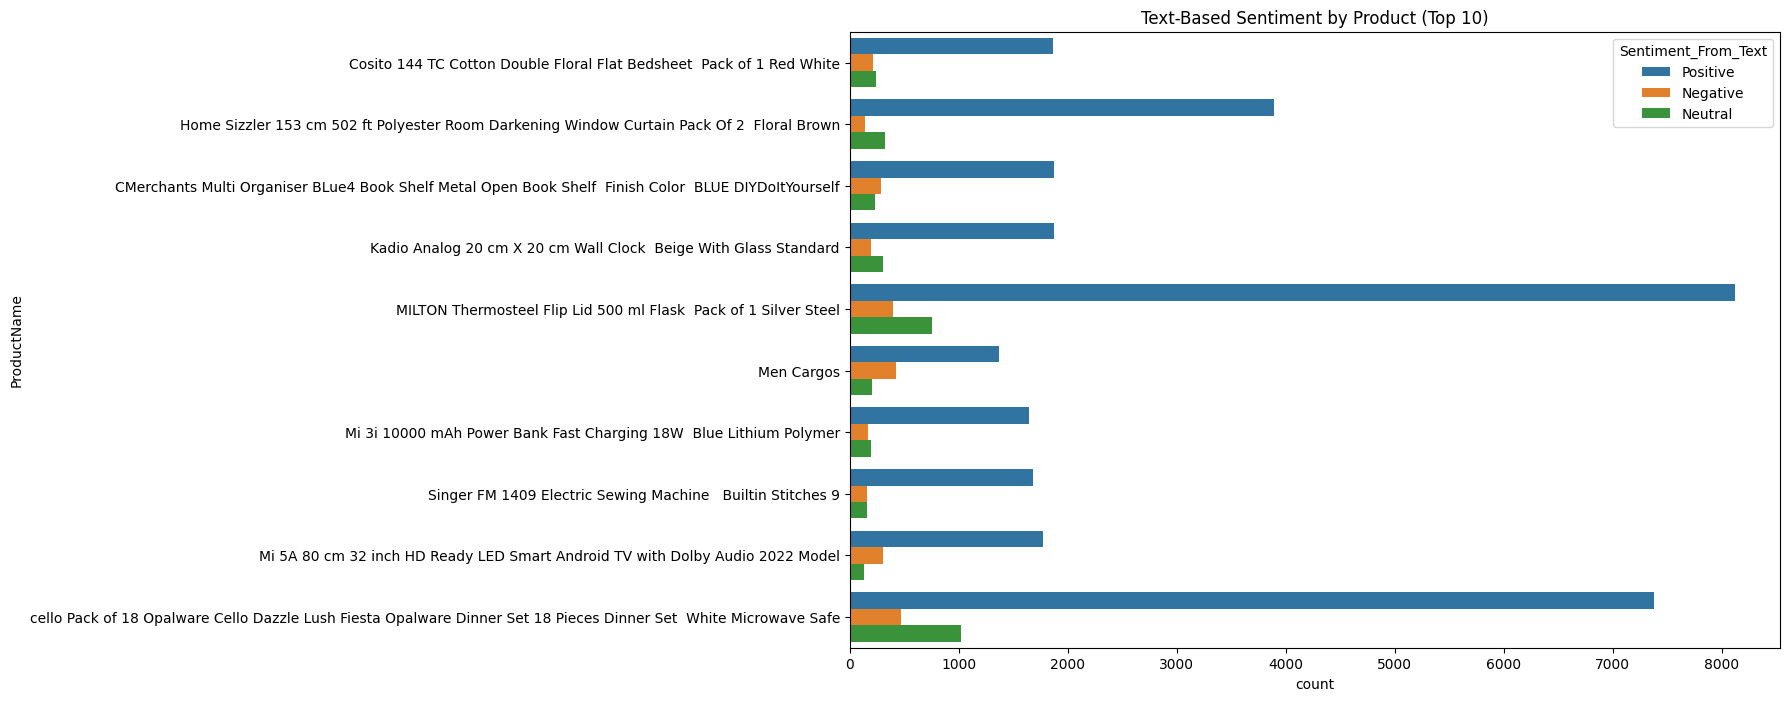

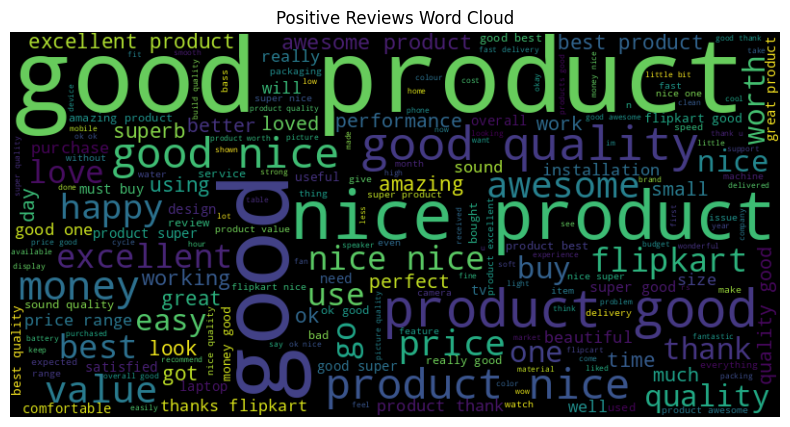

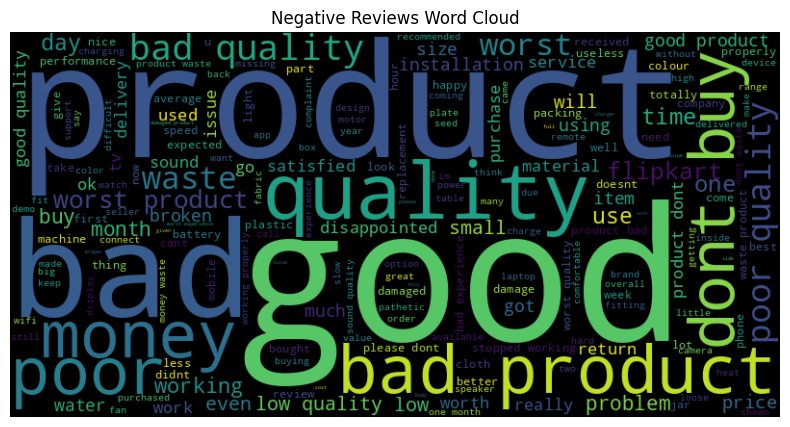

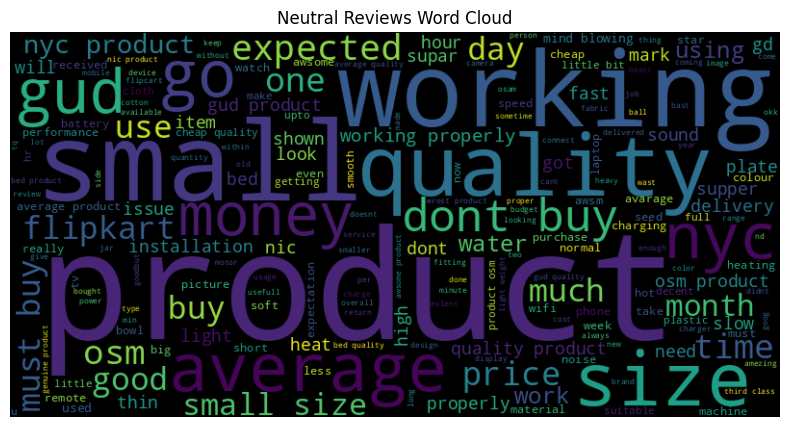

In [29]:
from wordcloud import WordCloud

# 1. Sentiment distribution (text-based)
plt.figure(figsize=(8, 6))
sns.countplot(x='Sentiment_From_Text', data=df)
plt.title('Text-Based Sentiment Distribution')
plt.show()

# 2. Sentiment distribution (rating-based)
plt.figure(figsize=(8, 6))
sns.countplot(x='Sentiment_From_Rate', data=df)
plt.title('Rating-Based Sentiment Distribution')
plt.show()

# 3. Sentiment by rating
plt.figure(figsize=(10, 6))
sns.countplot(x='Rate', hue='Sentiment_From_Text', data=df)
plt.title('Text-Based Sentiment by Star Rating')
plt.show()

# 4. Sentiment by product (top 10 products by review count)
top_products = df['ProductName'].value_counts().index[:10]
top_df = df[df['ProductName'].isin(top_products)]
plt.figure(figsize=(12, 8))
sns.countplot(y='ProductName', hue='Sentiment_From_Text', data=top_df)
plt.title('Text-Based Sentiment by Product (Top 10)')
plt.show()

# 5. Word clouds for positive and negative reviews
positive_reviews = ' '.join(df[df['Sentiment_From_Text'] == 'Positive']['Summary'])
negative_reviews = ' '.join(df[df['Sentiment_From_Text'] == 'Negative']['Summary'])
neutral_reviews = ' '.join(df[df['Sentiment_From_Text'] == 'Neutral']['Summary'])

# Positive word cloud
plt.figure(figsize=(10, 5))
wordcloud = WordCloud(width=800, height=400).generate(positive_reviews)
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Positive Reviews Word Cloud')
plt.show()

# Negative word cloud
plt.figure(figsize=(10, 5))
wordcloud = WordCloud(width=800, height=400).generate(negative_reviews)
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Negative Reviews Word Cloud')
plt.show()

# Neutral word cloud
plt.figure(figsize=(10, 5))
wordcloud = WordCloud(width=800, height=400).generate(neutral_reviews)
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Neutral Reviews Word Cloud')
plt.show()

**Summary of the project**
1. **Overall Sentiment Distribution**
  **Text Based Sentiment Distribution**
   The majority of reviews (approximately 140,000) are classified as Positive based on text analysis using VADER. Negative reviews number around 20,000, while Neutral reviews account for about 25,000. This indicates a strong positive bias in the text content of the reviews, suggesting that customers tend to express favorable opinions in their written feedback.
   
   **Rating Based Sentiment Distribution** Similarly, the sentiment derived from star ratings (mapped as 4-5 stars = Positive, 3 stars = Neutral, 1-2 stars = Negative) shows a dominant Positive category (around 140,000 reviews), with Neutral (approximately 20,000) and Negative (around 30,000) categories significantly lower. This alignment suggests that higher star ratings (4-5) are prevalent, consistent with the text-based findings.

2. Text-Based Sentiment by Star Rating
The distribution of text-based sentiment across star ratings reveals interesting patterns:
* 1-Star Ratings: Predominantly Negative (around 15,000), with minor Positive (a few thousand) and Neutral (a few thousand) classifications. This suggests that 1-star reviews align well with negative text sentiment, though some may contain sarcasm or mixed feedback misclassified as Positive or Neutral.
* 2-Star Ratings: Mostly Negative (around 10,000), with small Positive and Neutral counts, indicating a similar trend of negative sentiment in lower ratings.
* 3-Star Ratings: A balanced mix, with Positive (around 15,000), Negative (around 5,000), and Neutral (around 5,000) sentiments. This reflects the neutral nature of 3-star ratings, where text sentiment varies widely.
* 4-Star Ratings: Dominated by Positive sentiment (around 40,000), with minor Negative and Neutral contributions, showing a strong correlation between 4-star ratings and positive text.
* 5-Star Ratings: Overwhelmingly Positive (around 80,000), with negligible Negative and Neutral counts, reinforcing that 5-star reviews are highly likely to contain positive text.
* Observation: There’s a notable discrepancy where lower ratings (1-2 stars) occasionally yield Positive or Neutral text sentiment, possibly due to sarcasm, ambiguous language, or VADER’s limitations with Hinglish/slang. Higher ratings (4-5 stars) show strong alignment with Positive text sentiment.

3. Text-Based Sentiment by Top 10 Products
* The analysis of the top 10 products by review count shows a consistent trend of Positive sentiment dominating across all products:
* Products like "MILTON Thermosteel Flip Lid 500 ml Flask (Pack of 1 Silver Steel)" and "Cello Pack of 18 Opalware Cello Dazzle Lush Fiesta Opalware Dinner Set 18 Pieces Dinner Set, White Microwave Safe" have the highest review counts (over 7,000 and 6,000 respectively), with the vast majority classified as Positive.
* Other products, such as "Kadio Analog 20 cm x 20 cm Wall Clock Beige with Glass Standard" and "Mi 31 10000 mAh Power Bank Fast Charging 18W Blue Lithium Polymer," also lean heavily toward Positive sentiment (around 3,000-4,000 reviews each).
* Negative and Neutral sentiments are present but minimal across all products, with counts typically below 1,000 per product.
* Observation: The strong Positive bias across top products suggests either high customer satisfaction with these items or a potential presence of biased reviews (e.g., promotional or fake reviews). Neutral sentiment appears more in products with moderate review counts, possibly indicating mixed but not strongly negative feedback.


4. Implications and Insights
* Positive Bias: The overwhelming Positive sentiment in both text and ratings indicates that the dataset may be skewed toward satisfied customers or that Flipkart’s review system encourages positive feedback. This could also reflect a selection bias where only satisfied customers leave detailed reviews.
* Neutral Review Significance: The relatively low Neutral count (both text- and rating-based) suggests that customers either tend to express strong opinions (Positive or Negative) or that neutral experiences are underrepresented. The neutral word cloud (not shown but implied) could reveal terms like “okay,” “average,” or “decent,” highlighting products that meet basic expectations without exciting customers.
* Discrepancy Analysis: The mismatch between low ratings (1-2 stars) and occasional Positive/Neutral text sentiment warrants further investigation. It might indicate sarcasm, cultural nuances (e.g., Hinglish), or limitations in VADER’s ability to capture context, suggesting a need for advanced models like BERT or manual review of such cases.
* Product-Specific Trends: Top products with high Positive sentiment are likely popular or well-received items, but the low Negative/Neutral counts might mask underlying issues (e.g., delivery delays) that don’t significantly impact ratings.


5. Recommendations
* Refine Neutral Analysis: Generate and analyze the neutral word cloud to identify specific terms or themes (e.g., “delivery,” “price”) that might indicate subtle dissatisfaction or mediocrity, which could guide product improvements.
* Address Discrepancies: For 1-2 star reviews with Positive/Neutral text, consider sampling these reviews for manual analysis or applying a more context-aware model (e.g., BERT) to better capture sarcasm or mixed sentiments.
* Explore Bias: Investigate the dataset for potential review bias (e.g., fake reviews or selective posting) given the strong Positive skew, possibly by cross-referencing with external data or analyzing review timestamps.
Product Focus: Target products with moderate Neutral sentiment for enhancement, as they might represent untapped potential to shift customers to Positive feedback.


**Using RNNs for sentiment Analysis**

In [30]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical

# Use Summary column for analysis
texts = df['Summary'].values
labels = df['Rate'].apply(lambda x: 1 if x >= 4 else (0 if x == 3 else -1)).values

# Tokenization
max_words = 10000  # Vocabulary size
max_len = 100      # Maximum sequence length
tokenizer = Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(texts)
sequences = tokenizer.texts_to_sequences(texts)

# Pad sequences
X = pad_sequences(sequences, maxlen=max_len)
y = to_categorical(np.array(labels) + 1, num_classes=3)  # Shift to 0, 1, 2 for categorical

# Split into train and test sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [31]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

# Define the model
model = Sequential()
model.add(Embedding(max_words, 100, input_length=max_len))  # Embedding layer
model.add(LSTM(64, return_sequences=False))                 # LSTM layer
model.add(Dropout(0.2))                                    # Dropout to prevent overfitting
model.add(Dense(3, activation='softmax'))                   # Output layer (3 classes: Neg, Neu, Pos)

# Compile the model
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Train the model
history = model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(X_train, y_train, epochs=5, batch_size=32, validation_split=0.2)

# Evaluate
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {accuracy:.4f}")

Epoch 1/5
3798/3798 ━━━━━━━━━━━━━━━━━━━━ 175s 45ms/step - accuracy: 0.8697 - loss: 0.4006 - val_accuracy: 0.8949 - val_loss: 0.3205
Epoch 2/5
3798/3798 ━━━━━━━━━━━━━━━━━━━━ 171s 45ms/step - accuracy: 0.9028 - loss: 0.2985 - val_accuracy: 0.9004 - val_loss: 0.3034
Epoch 3/5
3798/3798 ━━━━━━━━━━━━━━━━━━━━ 171s 45ms/step - accuracy: 0.9089 - loss: 0.2778 - val_accuracy: 0.9006 - val_loss: 0.3054
Epoch 4/5
3798/3798 ━━━━━━━━━━━━━━━━━━━━ 172s 45ms/step - accuracy: 0.9143 - loss: 0.2660 - val_accuracy: 0.9009 - val_loss: 0.3121
Epoch 5/5
3798/3798 ━━━━━━━━━━━━━━━━━━━━ 173s 46ms/step - accuracy: 0.9216 - loss: 0.2442 - val_accuracy: 0.8973 - val_loss: 0.3295
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 20s 16ms/step - accuracy: 0.8982 - loss: 0.3212
Test Accuracy: 0.8980


In [35]:
# Predict on test set
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_test_classes = np.argmax(y_test, axis=1)

# Confusion matrix or classification report
from sklearn.metrics import classification_report
print(classification_report(y_test_classes, y_pred_classes, target_names=['Negative', 'Neutral', 'Positive']))

1187/1187 ━━━━━━━━━━━━━━━━━━━━ 19s 16ms/step
              precision    recall  f1-score   support

    Negative       0.87      0.83      0.85      5242
     Neutral       0.43      0.21      0.28      3038
    Positive       0.93      0.98      0.95     29692

    accuracy                           0.90     37972
   macro avg       0.74      0.67      0.69     37972
weighted avg       0.88      0.90      0.88     37972



The RNN model performs good with an overall accuracy of 0.90, particularly excelling with Positive reviews due to the dataset’s imbalance. However, its weakness with Neutral reviews (F1-score 0.28) suggests room for improvement, likely requiring techniques to address class imbalance and enhance model sensitivity to neutral text.

This model can be improved by increasing the robustness i.e increasin the number of epochs, using a pre-trained model like BERT, which might better handle neutral sentiment due to its contextual understanding.

**The sentiment analysis of the Flipkart product review dataset was conducted using two methods: text-based sentiment analysis with VADER and rating-based sentiment analysis with star ratings, supplemented by an RNN-based approach for deeper evaluation.**
**Both VADER and rating-based methods offer quick, interpretable insights with a positive skew, while the RNN enhances accuracy for dominant classes but needs refinement to handle neutral sentiment effectively. Combining these methods provides a comprehensive view, with the RNN offering potential for future improvement pending imbalance correction.**